# Statistical Time Series Models

## Overview :-

**What this notebook does :**
- forecasts each product's weekly sales with **6** classical time series models, using only the product's own past sales
- scores every model on the same **4** validation dates, products and weeks as the baselines
- compares the 6 models with the two baselines and chooses one

**Approach followed :**
- one model per product (100 products), fitted again on each validation date with only the weeks up to that date
- the model settings come from the time series analysis of the EDA : AR order **1** (PACF), MA order **1** (ACF), differencing per product from the ADF test, and one yearly seasonal term
- the main score is **Macro RMSSE**, the same as for the baselines

**Steps :**
- 1 . Import Required Modules
- 2 . Settings
- 3 . Data Reading
- 4 . Validation Rows and Baselines
- 5 . Differencing per Product (ADF)
- 6 . One Product by Hand
- 7 . Models : SES, AR, MA, ARMA, ARIMA, SARIMA
- 8 . Comparison

**Reads / Writes :**
- **Reads :** `data/prepared/weekly_sales.parquet`
- **Writes :** nothing, the chosen model is written in the conclusion

# 1 . Import Required Modules :-

In [1]:
## import the libraries used in this notebook
import numpy as np                          # import numpy library for numerical calculation
import pandas as pd                         # import pandas library for reading the data
import matplotlib.pyplot as plt             # import matplotlib library for plotting graphs
import seaborn as sns                       # import seaborn library for data visualisation
%matplotlib inline

import warnings                             # import warnings to ignore future and fitting warnings
warnings.filterwarnings('ignore')

# 2 . Settings :-

- **DATA_DIR :** folder with the prepared dataset

In [2]:
## folder of the prepared data
DATA_DIR = '../data/prepared/'                                            # prepared data folder

# 3 . Data Reading :-

The models use the weekly sales only, one row per product and one column per week. The forecast dates are the same as in the split notebook : **4** validation dates, **4** weeks ahead each.

In [3]:
## read the dataset, one row per product and one column per week, and set the validation dates
full_data = pd.read_parquet(DATA_DIR + 'weekly_sales.parquet')            # weekly sales of the 100 products

data = full_data.pivot(index='item_id', columns='week', values='sales').sort_index().astype(float)
weeks = data.columns                                                      # all weeks in order
items = data.index                                                        # all products in order
first_sale_date = full_data.groupby('item_id')['first_sale_date'].first().loc[items]
first = np.searchsorted(weeks.values, first_sale_date.values)            # first sales week of each product

H = 4                                                                     # weeks to forecast
VALID_DATES = pd.to_datetime(['2015-10-18', '2015-11-15', '2015-12-13', '2016-01-10'])

print("Products x weeks : ", data.shape)

Products x weeks :  (100, 176)


# 4 . Validation Rows and Baselines :-

The validation rows, the two baselines, the RMSSE scale and the score function are built the same way as in the split notebook, so the statistical models are scored on exactly the same rows.

In [4]:
## one row per product, validation date and week ahead, with the actual sales, both baselines and the RMSSE scale
fc, scales = [], []
for origin in VALID_DATES:
    t = weeks.get_loc(origin)               # position of the forecast date
    for h in range(1, H + 1):
        fc.append(pd.DataFrame({'item_id': items, 'origin': origin, 'h': h,
                                'actual': data.values[:, t + h],
                                'y_pr_last': data.values[:, t],               # Last Week Naive
                                'y_pr_snaive': data.values[:, t + h - 52]}))  # Seasonal Naive
    for i in range(len(items)):
        change = np.diff(data.values[i, first[i]:t + 1])                  # weekly changes up to the forecast date
        scales.append({'item_id': items[i], 'origin': origin, 'scale_sq': np.mean(change ** 2)})
fc = pd.concat(fc, ignore_index=True).merge(pd.DataFrame(scales), on=['item_id', 'origin'], how='left')

print("Validation rows : ", fc.shape[0], " (4 dates x 100 products x 4 weeks)")

Validation rows :  1600  (4 dates x 100 products x 4 weeks)


In [5]:
## score functions : one date, and the average over the 4 validation dates
def evaluate(fc, pred):
    error = fc['actual'] - fc[pred]
    item = pd.DataFrame({'item_id': fc['item_id'], 'sq': error ** 2, 'scale_sq': fc['scale_sq']}).groupby('item_id').mean()
    rmsse = np.sqrt(item['sq'] / item['scale_sq'].where(item['scale_sq'] > 0))       # one value per product
    return {'Macro RMSSE': rmsse.mean(), 'MAE': error.abs().mean(), 'RMSE': np.sqrt((error ** 2).mean()),
            'WAPE': error.abs().sum() / fc['actual'].sum(), 'Bias': -error.mean()}

def score(pred):
    by_date = pd.DataFrame([evaluate(fc[fc['origin'] == i], pred) for i in VALID_DATES])
    result = by_date.mean().to_dict()
    result['RMSSE std'] = by_date['Macro RMSSE'].std()                    # spread over the 4 dates
    return result

pd.DataFrame([{'Model': 'Last Week Naive', **score('y_pr_last')},
              {'Model': 'Seasonal Naive', **score('y_pr_snaive')}]).round(4)

,Model,Macro RMSSE,MAE,RMSE,WAPE,Bias,RMSSE std
0,Last Week Naive,0.8478,20.5175,39.1056,0.3021,2.1400,0.0840
1,Seasonal Naive,1.2838,29.5312,45.2285,0.4365,6.3062,0.0725


### Insights :-
- The baselines score the same as in the split notebook (Last Week Naive **0.8478**, Seasonal Naive **1.2838**), so the validation rows are the same.

# 5 . Differencing per Product (ADF) :-

AR, MA and ARMA assume a stationary series. ARIMA and SARIMA difference a product when it drifts : **d = 1** if the ADF p-value is **0.05** or more, else **d = 0**. The test is run again on every validation date, with only the weeks known on that date.

In [6]:
## d of every product on every validation date, from the ADF test on the weeks up to that date
from statsmodels.tsa.stattools import adfuller                            # import ADF test

d_rows = []
for origin in VALID_DATES:
    t = weeks.get_loc(origin)
    for i in range(len(items)):
        p_value = adfuller(data.values[i, first[i]:t + 1])[1]             # weeks from the first sale up to the date
        d_rows.append({'item_id': items[i], 'origin': origin, 'd': int(p_value >= 0.05)})
d_table = pd.DataFrame(d_rows).set_index(['origin', 'item_id'])['d']

d_table.groupby('origin').sum().rename('products with d = 1').to_frame()

,products with d = 1
origin,
2015-10-18,39
2015-11-15,32
2015-12-13,38
2016-01-10,38


### Insights :-
- On the 4 validation dates, **39, 32, 38** and **38** products drift and get **d = 1**, the others get **d = 0**.
- The number changes a little from date to date, because each test uses only the weeks known on that date.

# 6 . One Product by Hand :-

The six models, with the same small orders so the comparison shows what each idea adds :
- **( a ) . SES :** a smoothed level, recent weeks count more
- **( b ) . AR(1) :** next week depends on this week
- **( c ) . MA(1) :** next week depends on the last forecast error
- **( d ) . ARMA(1,1) :** both together
- **( e ) . ARIMA(1,d,1) :** ARMA on the weekly changes when the product drifts (d = 1)
- **( f ) . SARIMA(1,d,1)(1,0,0,52) :** ARIMA plus one yearly term, the same week 52 weeks before

AR, MA and ARMA get a constant (the average level). ARIMA and SARIMA get it only when d = 0. One function fits any of the six, so the same steps run for every model.

In [7]:
## function that forecasts the next H weeks of one series with one of the six models
from statsmodels.tsa.holtwinters import SimpleExpSmoothing                # import simple exponential smoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX                    # import ARIMA family models
warnings.simplefilter('ignore')                                           # statsmodels turns its fitting warnings back on

def fit_forecast(name, y, d):
    ## returns the forecast and True if the fit converged
    if name == 'SES':
        return SimpleExpSmoothing(y, initialization_method='estimated').fit().forecast(H), True
    orders = {'AR': ((1, 0, 0), (0, 0, 0, 0)), 'MA': ((0, 0, 1), (0, 0, 0, 0)), 'ARMA': ((1, 0, 1), (0, 0, 0, 0)),
              'ARIMA': ((1, d, 1), (0, 0, 0, 0)), 'SARIMA': ((1, d, 1), (1, 0, 0, 52))}
    order, seasonal = orders[name]
    trend = 'c' if order[1] == 0 else 'n'                                 # a constant only without differencing
    res = SARIMAX(y, order=order, seasonal_order=seasonal, trend=trend).fit(disp=False)
    return res.forecast(H), res.mle_retvals['converged']

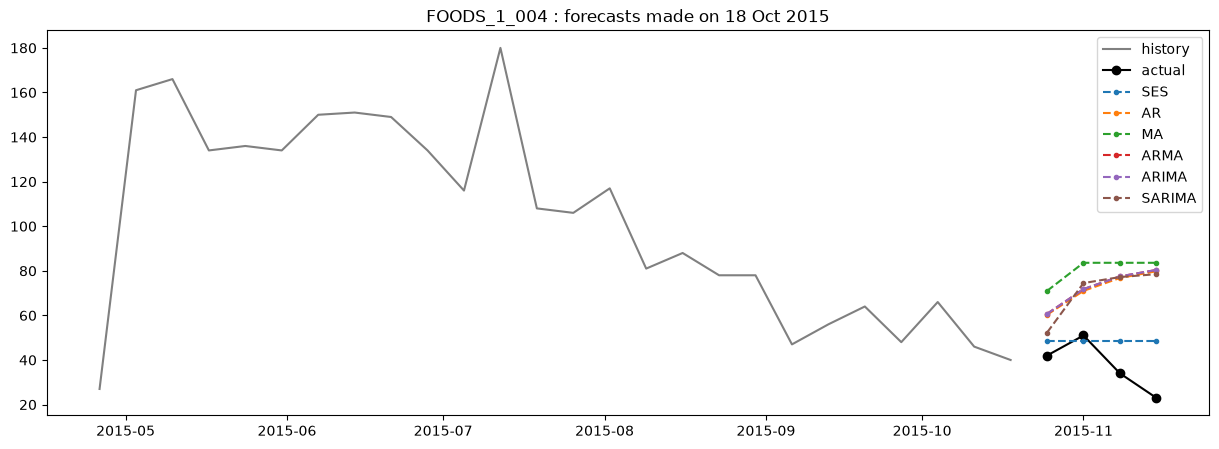

d of this product :  0


,week,actual,SES,AR,MA,ARMA,ARIMA,SARIMA
0,2015-10-25,42.0,48.5,60.3,71.0,60.7,60.7,52.3
1,2015-11-01,51.0,48.5,71.0,83.6,71.8,71.8,74.5
2,2015-11-08,34.0,48.5,76.8,83.6,77.5,77.5,77.2
3,2015-11-15,23.0,48.5,79.8,83.6,80.4,80.4,78.5


In [8]:
## the six forecasts of FOODS_1_004 at the first validation date, next to the actual sales
i = list(items).index('FOODS_1_004')
t = weeks.get_loc(VALID_DATES[0])
y = data.values[i, first[i]:t + 1]                                        # weeks known on 18 Oct 2015
d = d_table[(VALID_DATES[0], 'FOODS_1_004')]

example = pd.DataFrame({'week': weeks[t + 1:t + H + 1], 'actual': data.values[i, t + 1:t + H + 1]})
for name in ['SES', 'AR', 'MA', 'ARMA', 'ARIMA', 'SARIMA']:
    example[name] = np.asarray(fit_forecast(name, y, d)[0]).round(1)

plt.figure(figsize=(15,5))                  # Set Canvas size
plt.plot(weeks[t - 25:t + 1], data.values[i, t - 25:t + 1], color='grey', label='history')
plt.plot(example['week'], example['actual'], color='black', marker='o', label='actual')
for name in ['SES', 'AR', 'MA', 'ARMA', 'ARIMA', 'SARIMA']:
    plt.plot(example['week'], example[name], linestyle='dashed', marker='.', label=name)
plt.legend()
plt.title("FOODS_1_004 : forecasts made on 18 Oct 2015")
plt.show()

print("d of this product : ", d)
example

### Insights :-
- FOODS_1_004 has **d = 0**, so ARIMA is the same as ARMA for it (both **60.7, 71.8, 77.5, 80.4**).
- The actual sales were **42, 51, 34** and **23**. **SES** forecasts **48.5** for all 4 weeks and is the closest.
- AR, ARMA, ARIMA and SARIMA expect the sales to climb back towards the product's longer average, and MA jumps to that average (**83.6**) after 1 week. The sales went down instead.

# 7 . Models :-

Every model is fitted on **100** products x **4** validation dates = **400** series. If a fit fails, that product gets the Last Week Naive forecast, and a negative forecast is set to **0**. Fits that stop before the optimiser converges still give a forecast, and they are counted too.

In [9]:
## function that runs one model on every product and validation date, and adds its forecasts to the validation rows
def run_model(name, col):
    rows, n_failed, n_clipped, n_not_converged = [], 0, 0, 0
    for origin in VALID_DATES:
        t = weeks.get_loc(origin)
        for i in range(len(items)):
            y = data.values[i, first[i]:t + 1]                            # weeks from the first sale up to the date
            try:
                pred, converged = fit_forecast(name, y, d_table[(origin, items[i])])
                pred = np.asarray(pred, dtype=float)
                n_not_converged = n_not_converged + int(not converged)
                if not np.isfinite(pred).all():
                    raise ValueError("forecast is not a number")
            except Exception:
                pred = np.repeat(y[-1], H)                                # Last Week Naive instead
                n_failed = n_failed + 1
            n_clipped = n_clipped + int((pred < 0).sum())
            for h in range(1, H + 1):
                rows.append({'item_id': items[i], 'origin': origin, 'h': h, col: max(pred[h - 1], 0)})
    counts = {'Failed fits': n_failed, 'Clipped': n_clipped, 'Not converged': n_not_converged}
    return fc.drop(columns=col, errors='ignore').merge(pd.DataFrame(rows), on=['item_id', 'origin', 'h']), counts

counts = {}                                                               # failed, clipped and not converged per model

## ( a ) . SES :-

Simple exponential smoothing : the forecast is a weighted average of past weeks, with weights that shrink for older weeks. All 4 weeks ahead get the same value.

In [10]:
## forecast all products on the 4 validation dates with SES, and score it
fc, counts['SES'] = run_model('SES', 'y_pr_ses')
pd.DataFrame([{**score('y_pr_ses'), **counts['SES']}]).round(4)

,Macro RMSSE,MAE,RMSE,WAPE,Bias,RMSSE std,Failed fits,Clipped,Not converged
0,0.7639,19.2649,37.3759,0.2837,3.0435,0.0821,0,0,0


### Insights :-
- SES has a Macro RMSSE of **0.7639**, about **10 %** better than Last Week Naive (**0.8478**).
- Its bias is low (**+3.04**), and every fit worked : **0** failed, **0** clipped, **0** not converged.
- It moves from date to date about as much as Last Week Naive (std **0.0821** against **0.0840**).

## ( b ) . AR(1) :-

The next week is a constant plus a share of this week. The forecast moves back towards the product's average the further ahead it goes.

In [11]:
## forecast all products on the 4 validation dates with AR, and score it
fc, counts['AR'] = run_model('AR', 'y_pr_ar')
pd.DataFrame([{**score('y_pr_ar'), **counts['AR']}]).round(4)

,Macro RMSSE,MAE,RMSE,WAPE,Bias,RMSSE std,Failed fits,Clipped,Not converged
0,0.878,20.9071,36.2538,0.309,6.0648,0.0401,0,0,0


### Insights :-
- AR(1) scores **0.8780**, worse than Last Week Naive.
- It pulls the forecast back towards the product's average too quickly, and it forecasts too high on average (bias **+6.06**).

## ( c ) . MA(1) :-

The next week is the average plus a share of the last forecast error. After 1 week ahead it is just the average.

In [12]:
## forecast all products on the 4 validation dates with MA, and score it
fc, counts['MA'] = run_model('MA', 'y_pr_ma')
pd.DataFrame([{**score('y_pr_ma'), **counts['MA']}]).round(4)

,Macro RMSSE,MAE,RMSE,WAPE,Bias,RMSSE std,Failed fits,Clipped,Not converged
0,1.025,25.6617,43.7927,0.38,8.4789,0.0496,0,0,0


### Insights :-
- MA(1) is the weakest of the six : **1.0250**, so its errors are bigger than a normal weekly change.
- After 1 week ahead it only forecasts the product's average, which misses the recent level.

## ( d ) . ARMA(1,1) :-

AR(1) and MA(1) together.

In [13]:
## forecast all products on the 4 validation dates with ARMA, and score it
fc, counts['ARMA'] = run_model('ARMA', 'y_pr_arma')
pd.DataFrame([{**score('y_pr_arma'), **counts['ARMA']}]).round(4)

,Macro RMSSE,MAE,RMSE,WAPE,Bias,RMSSE std,Failed fits,Clipped,Not converged
0,0.7844,19.3679,35.0258,0.2863,6.1034,0.0382,0,0,18


### Insights :-
- ARMA(1,1) scores **0.7844**, much better than AR or MA alone, and it beats Last Week Naive.
- It is the steadiest model across the 4 dates (std **0.0382**).
- **18** of its 400 fits stopped before converging, but they still gave usable forecasts.

## ( e ) . ARIMA(1,d,1) :-

ARMA(1,1) on the weekly changes for the products that drift (d = 1), and on the sales for the others (d = 0).

In [14]:
## forecast all products on the 4 validation dates with ARIMA, and score it
fc, counts['ARIMA'] = run_model('ARIMA', 'y_pr_arima')
pd.DataFrame([{**score('y_pr_arima'), **counts['ARIMA']}]).round(4)

,Macro RMSSE,MAE,RMSE,WAPE,Bias,RMSSE std,Failed fits,Clipped,Not converged
0,0.7797,19.3593,35.053,0.286,6.166,0.0402,0,0,6


### Insights :-
- ARIMA(1,d,1) scores **0.7797**, slightly better than ARMA (**0.7844**), so differencing the drifting products helps a little.
- **6** of its 400 fits did not converge.

## ( f ) . SARIMA(1,d,1)(1,0,0,52) :-

ARIMA plus one yearly term : the same week 52 weeks before. This model takes about a second per series, so it runs for a few minutes.

In [15]:
## forecast all products on the 4 validation dates with SARIMA, and score it
fc, counts['SARIMA'] = run_model('SARIMA', 'y_pr_sarima')
pd.DataFrame([{**score('y_pr_sarima'), **counts['SARIMA']}]).round(4)

,Macro RMSSE,MAE,RMSE,WAPE,Bias,RMSSE std,Failed fits,Clipped,Not converged
0,0.7691,18.8224,33.9426,0.2779,6.5819,0.0411,0,0,53


### Insights :-
- SARIMA scores **0.7691**, the best of the ARIMA family, and it has the lowest MAE (**18.82**), RMSE (**33.94**) and WAPE (**27.8 %**) of all models.
- But **53** of its 400 fits (**13 %**) did not converge, it has the highest bias of the six (**+6.58**), and it takes most of this notebook's run time.

# 8 . Comparison :-

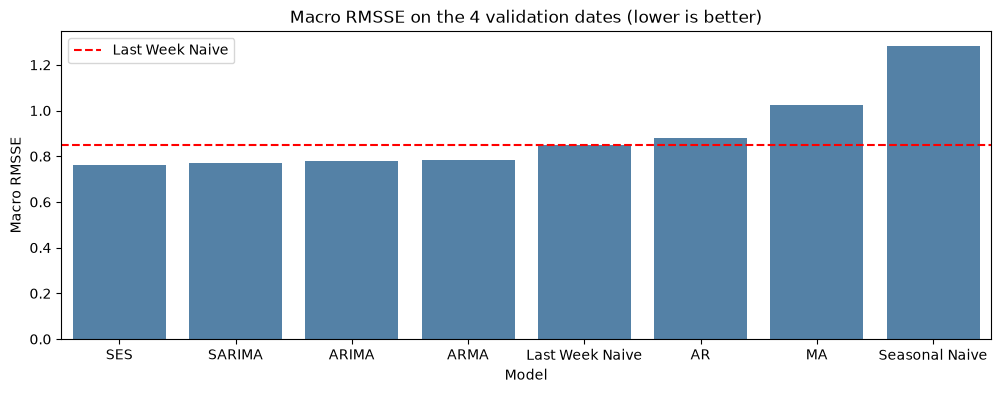

,Model,Macro RMSSE,MAE,RMSE,WAPE,Bias,RMSSE std,Failed fits,Clipped,Not converged
0,SES,0.7639,19.2649,37.3759,0.2837,3.0435,0.0821,0.0,0.0,0.0
1,SARIMA,0.7691,18.8224,33.9426,0.2779,6.5819,0.0411,0.0,0.0,53.0
2,ARIMA,0.7797,19.3593,35.0530,0.2860,6.1660,0.0402,0.0,0.0,6.0
3,ARMA,0.7844,19.3679,35.0258,0.2863,6.1034,0.0382,0.0,0.0,18.0
4,Last Week Naive,0.8478,20.5175,39.1056,0.3021,2.1400,0.0840,0.0,0.0,0.0
5,AR,0.8780,20.9071,36.2538,0.3090,6.0648,0.0401,0.0,0.0,0.0
6,MA,1.0250,25.6617,43.7927,0.3800,8.4789,0.0496,0.0,0.0,0.0
7,Seasonal Naive,1.2838,29.5312,45.2285,0.4365,6.3062,0.0725,0.0,0.0,0.0


In [16]:
## all six models next to the two baselines, best Macro RMSSE first
models = {'Last Week Naive': 'y_pr_last', 'Seasonal Naive': 'y_pr_snaive', 'SES': 'y_pr_ses', 'AR': 'y_pr_ar',
          'MA': 'y_pr_ma', 'ARMA': 'y_pr_arma', 'ARIMA': 'y_pr_arima', 'SARIMA': 'y_pr_sarima'}

Results = pd.DataFrame([{'Model': i, **score(models[i]), **counts.get(i, {})} for i in models])
Results = Results.fillna(0).sort_values('Macro RMSSE').reset_index(drop=True)          # baselines have no fits

plt.figure(figsize=(12,4))                  # Set Canvas size
sns.barplot(x='Model', y='Macro RMSSE', data=Results, color='steelblue')
plt.axhline(Results.loc[Results['Model'] == 'Last Week Naive', 'Macro RMSSE'].iloc[0], color='red', linestyle='dashed', label='Last Week Naive')
plt.legend()
plt.title("Macro RMSSE on the 4 validation dates (lower is better)")
plt.show()

Results.round(4)

In [17]:
## Macro RMSSE of every model on each validation date
by_date = pd.DataFrame({i: [evaluate(fc[fc['origin'] == j], models[i])['Macro RMSSE'] for j in VALID_DATES]
                        for i in models}, index=VALID_DATES.date)
by_date.round(4)

,Last Week Naive,Seasonal Naive,SES,AR,MA,ARMA,ARIMA,SARIMA
2015-10-18,0.9439,1.2172,0.8634,0.8763,0.9608,0.8163,0.8191,0.8163
2015-11-15,0.7529,1.2351,0.6756,0.8236,1.0121,0.7411,0.7325,0.7221
2015-12-13,0.8854,1.3755,0.7933,0.9182,1.0555,0.8167,0.8064,0.7869
2016-01-10,0.8091,1.3072,0.7232,0.8938,1.0716,0.7635,0.7610,0.7510


### Insights :-
- **4** of the 6 models beat Last Week Naive (**0.8478**) : SES **0.7639**, SARIMA **0.7691**, ARIMA **0.7797** and ARMA **0.7844**. AR (**0.8780**) and MA (**1.0250**) do not.
- SES has the best average, and SARIMA is only **0.7 %** behind.
- On single dates SES and SARIMA each win **2** of the 4 : SES on 15 Nov and 10 Jan, SARIMA on 13 Dec and (with ARMA) on 18 Oct. Both beat Last Week Naive on every date.
- SARIMA is steadier (std **0.0411** against **0.0821**) and has lower MAE and RMSE. SES has half the bias (**+3.04** against **+6.58**), so it overstocks less.
- No fit failed and no forecast had to be clipped.
- Since the two are within 1 %, the simpler model is chosen : **SES**. It has one setting, always converges and runs in seconds, while 13 % of the SARIMA fits did not converge.

# ----- CONCLUSION -----

- Six classical models were fitted on **100** products x **4** validation dates, each using only the product's own past sales.
- **4** of them beat Last Week Naive (**0.8478**) : SES **0.7639**, SARIMA **0.7691**, ARIMA **0.7797** and ARMA **0.7844**. AR and MA alone are worse, and MA is the weakest (**1.0250**).
- Adding ideas to the ARMA family helps a little each time : ARMA **0.7844** -> ARIMA (differencing) **0.7797** -> SARIMA (yearly term) **0.7691**. This matches the EDA : a weak yearly pattern and some drifting products.
- **Chosen statistical model : SES.** It has the best average Macro RMSSE, about **10 %** better than Last Week Naive and better on all 4 dates, the lowest bias of the six (**+3.04**), and it is the simplest.
- **Runner-up : SARIMA**, only 0.7 % behind and steadier across dates, but **13 %** of its fits did not converge and it is much slower.
- SES now goes to model selection, against the machine learning model and the baselines. The test date has not been used.